# Exploration du dataset

### Lecture du dataset

In [7]:
import pandas as pd

df=pd.read_csv('../datasets/original/perfumes.csv')

### Premières informations

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1479 entries, 0 to 1478
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                1479 non-null   object 
 1   name              1479 non-null   object 
 2   house_id          1479 non-null   object 
 3   house             1479 non-null   object 
 4   year              80 non-null     float64
 5   perfumers         69 non-null     object 
 6   concentration     1228 non-null   object 
 7   family            1479 non-null   object 
 8   secondary_family  1075 non-null   object 
 9   character         1479 non-null   object 
 10  seasons           1479 non-null   object 
 11  times_of_day      1479 non-null   object 
 12  top_notes         1388 non-null   object 
 13  heart_notes       1388 non-null   object 
 14  base_notes        1388 non-null   object 
 15  notes             1479 non-null   object 
 16  description       1479 non-null   object 


Nous avons donc un dataset avec 19 features et 1479 observations. 17 features sont en format objet, et 2 sont en format float. Les comptes de non null par lignes semblent très déséquilibrés.

In [9]:
df.head()

,id,name,house_id,house,year,perfumers,concentration,family,secondary_family,character,seasons,times_of_day,top_notes,heart_notes,base_notes,notes,description,popularity_rank,url
0,ysl-libre,Libre,ysl,Yves Saint Laurent,NaN,NaN,eau-de-parfum,White Bloom,NaN,floral; creamy; fresh; citrusy,spring; summer; autumn,day; evening,Mandarin; Neroli; Lavender,Orange Blossom; Jasmine Sambac,Musk; Vanilla,Mandarin; Neroli; Lavender; Orange Blossom; Ja...,Mandarin and neroli brighten a creamy bloom of...,2.0,https://www.scento.com/perfumes/libre-yves-sai...
1,guerlain-shalimar,Shalimar,guerlain,Guerlain,NaN,NaN,eau-de-parfum,Petal Garden,Velvet Sweet,floral; sweet; warm; powdery,spring; summer; autumn,day; evening,Floral notes; Bergamot,Iris; Jasmine; Rose,Vanilla; Opoponax; Tonka Bean,Floral notes; Bergamot; Iris; Jasmine; Rose; V...,Floral notes and a flash of bergamot sit above...,3.0,https://www.scento.com/perfumes/shalimar-eau-d...
2,tom-ford-oud-wood,Oud Wood,tom-ford,Tom Ford,NaN,NaN,eau-de-parfum,Spice Route,NaN,warm; spicy; sweet; earthy,autumn; winter,evening; night,NaN,NaN,NaN,Cardamom; Pink Pepper; Patchouli; Amber; Oud; ...,Smooth woods and spice: cardamom and pink pepp...,4.0,https://www.scento.com/perfumes/oud-wood-tom-ford
3,creed-aventus,Aventus,creed,Creed,2010.0,Erwin Creed; Jean-Christophe Hérault,eau-de-parfum,Orchard Fruit,Wood & Root,fruity; earthy; citrusy; floral,spring; summer; autumn,day; evening,Lemon; Pink Pepper; Apple; Bergamot; Blackcurrant,Pineapple; Jasmine; Patchouli,Birch; Ambroxan; Cedarwood; Oakmoss; Musk,Lemon; Pink Pepper; Apple; Bergamot; Blackcurr...,Sparkling lemon and blackcurrant open onto pin...,5.0,https://www.scento.com/perfumes/aventus-creed
4,mfk-baccarat-rouge-540,Baccarat Rouge 540,mfk,Maison Francis Kurkdjian,NaN,NaN,eau-de-parfum,Wood & Root,White Bloom,woody; warm; floral; spicy,autumn; winter; spring,day; evening,Jasmine; Saffron,Cedarwood,Ambergris,Jasmine; Saffron; Cedarwood; Ambergris,"Jasmine and saffron open airy and golden, held...",6.0,https://www.scento.com/perfumes/baccarat-rouge...


Les 5 premières lignes nous montrent un dataset avec beaucoup d'informations différentes disponibles : les variables semblent pertinentes pour notre projet mais beaucoup de NaN sont présents. Il faudra étudier par la suite quelles colonnes seront à garder et quelles colonnes seront à supprimer selon leur importance et leur pertinence pour nos modèles.

In [10]:
df.describe()

,year,popularity_rank
count,80.000000,613.000000
mean,2006.987500,534.814029
std,21.268324,331.840030
min,1911.000000,2.000000
25%,2004.750000,250.000000
50%,2013.000000,512.000000
75%,2020.000000,803.000000
max,2025.000000,1196.000000


La fonction describe ne nous renvoie que les colonnes en format numériques car les autres sont des objets. 

On constate ici que seulement 80 valeurs sont renseignées pour l'année, ce qui semble peu par rapport au nombre d'observation.
Au niveau du rang de popularité, 613 valeurs sont présentes, soit un peu moins de la moitié du nombre d'observation. Ces variables présentent donc beaucoup de valeurs manquantes

Les années renseignées vont de 1911 à 2025. Concernant le classement de popularité, la médiane est de 512 et la moyenne d'environ 535. Il ne semble pas y avoir de valeur aberrantes.

### Valeurs manquantes

In [11]:
print(df.isnull().sum())

id                     0
name                   0
house_id               0
house                  0
year                1399
perfumers           1410
concentration        251
family                 0
secondary_family     404
character              0
seasons                0
times_of_day           0
top_notes             91
heart_notes           91
base_notes            91
notes                  0
description            0
popularity_rank      866
url                    0
dtype: int64


In [14]:
(df.isnull().sum() / len(df) * 100).round(2)

id                   0.00
name                 0.00
house_id             0.00
house                0.00
year                94.59
perfumers           95.33
concentration       16.97
family               0.00
secondary_family    27.32
character            0.00
seasons              0.00
times_of_day         0.00
top_notes            6.15
heart_notes          6.15
base_notes           6.15
notes                0.00
description          0.00
popularity_rank     58.55
url                  0.00
dtype: float64

Beaucoup de valeurs sont nulles dans les colonnes années (1399 soit 94,6%), parfumeurs (1410 soit 95,3%) et popularité (866 soit 58,6%). Ces taux sont trop importants pour envisager de remplacer les null par une moyenne ou une médiane. 

Il faudra donc, lors du nettoyage, évaluer l'intéret de ces variables en fonction de leur utilité pour le système de recommandation.

### Doublons

In [12]:
df.duplicated().sum()

np.int64(0)

Aucune ligne complète n'est dupliquée. C'est une bonne chose pour notre nettoyage.

In [13]:
df['id'].duplicated().sum()

np.int64(0)

De la même manière, on constate qu'aucun id de parfum n'est dupliqué. C'est positif concernant la qualité du dataset.

### Etude des familles olfactives

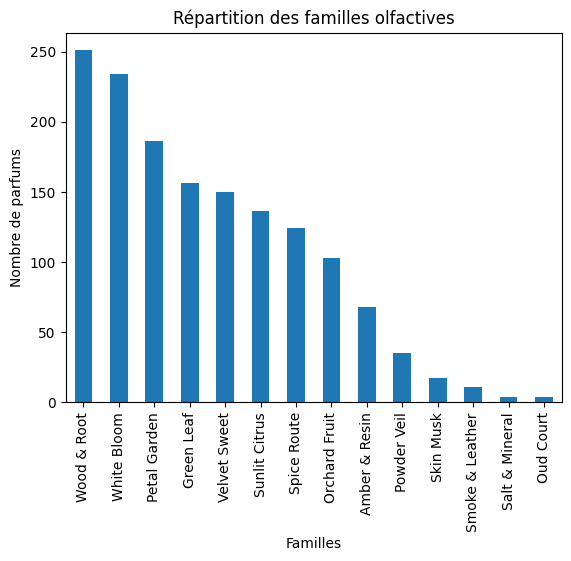

In [17]:
import matplotlib.pyplot as plt
df['family'].value_counts().plot(kind='bar')
plt.title('Répartition des familles olfactives')
plt.xlabel('Familles')
plt.ylabel('Nombre de parfums')
plt.show()

Sur ce diagramme en barres, on observe un déséquilibre entre les familles olfactives. Nous avons dans notre dataset une majorité de catégorie de Wood&Root, White Bloom et Petal Garden (entre 190 et 250 échantillons environs), tandis que la classe minoritaire (Oud Court) n'en contient qu'environ 10. Nous devrons prendre cela en compte lors de la mise en place de nos modèles.

### Caractéristiques des parfums

In [30]:
df['character'].str.split('; ').explode().value_counts()

character
floral      885
warm        780
citrusy     573
fresh       526
sweet       433
spicy       392
woody       361
fruity      358
earthy      262
creamy      253
herbal      247
powdery     188
resinous    157
musky       117
green       112
amber        84
smoky        61
clean        26
salty        25
leathery     14
rich          5
Name: count, dtype: int64

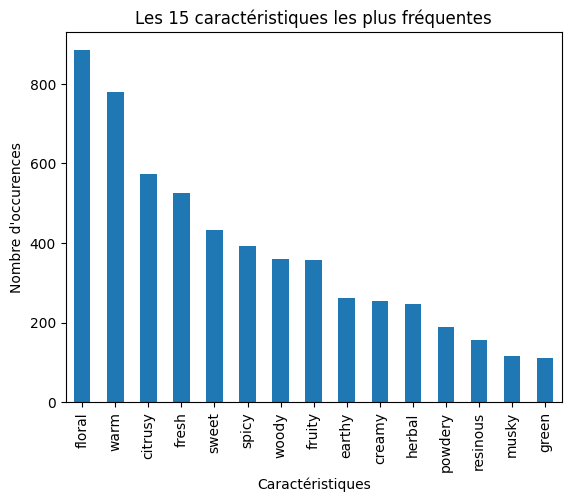

In [31]:
df['character'].str.split('; ').explode().value_counts().head(15).plot(kind='bar')
plt.title('Les 15 caractéristiques les plus fréquentes')
plt.xlabel('Caractéristiques')
plt.ylabel("Nombre d'occurences")
plt.show()

Dans ce dataset, les parfums sont décrits avec des mots clés correspondant à des caractères. On observe ici qu'un grand nombre de parfum sont décrit avec les termes floral (885) ou warm (780), suivis de citrusy et fresh. Cela permettra à l'utilisateur de décrire l'ambiance et le profil recherché

### Saisons et moments de la journées

In [32]:
df['seasons'].str.split('; ').explode().value_counts()

seasons
autumn    1442
spring    1414
summer     880
winter     599
Name: count, dtype: int64

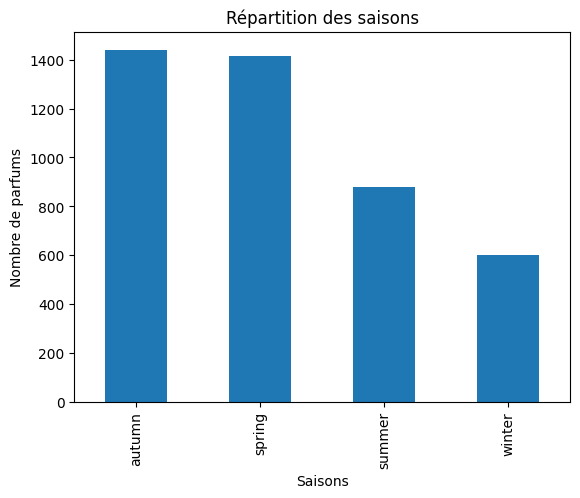

In [33]:
df['seasons'].str.split('; ').explode().value_counts().plot(kind='bar')
plt.title('Répartition des saisons')
plt.xlabel('Saisons')
plt.ylabel('Nombre de parfums')
plt.show()

Les saisons sont représentées de manière assez inégales : les associations avec automnes (1442) et printemps (1414) sont plus fréquentes que l'été (880) et l'hiver (599).

In [34]:
df['times_of_day'].str.split('; ').explode().value_counts()

times_of_day
evening    1442
day        1414
night        65
Name: count, dtype: int64

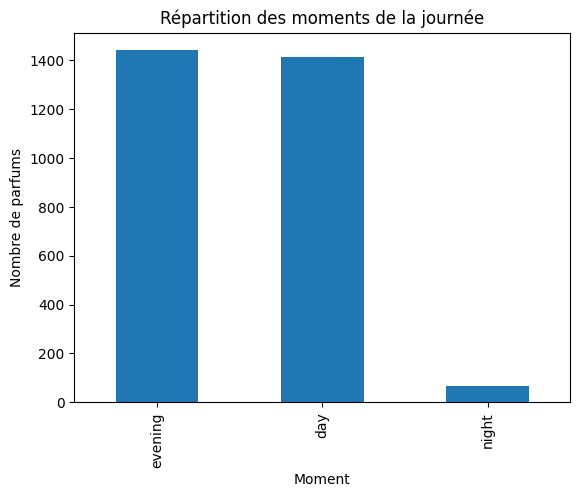

In [35]:
df['times_of_day'].str.split('; ').explode().value_counts().plot(kind='bar')
plt.title('Répartition des moments de la journée')
plt.xlabel('Moment')
plt.ylabel('Nombre de parfums')
plt.show()

Concernant les moments de la journée, la quasi totalité des parfums contiennent les mots clés evening et day. La catégorie de parfum adaptés à la nuit semble très séléctif.

Ces variables seront utiles pour personnaliser les recommandations faites à l'utilisateur selon le contexte qu'il mentionnera. 

**Pour ces deux sous-parties, il faut noter que plusieurs mots clés peuvent être écrits dans chaque colonnes.**

### Etude des notes olfactives

In [37]:
df['top_notes'].str.split('; ').explode().value_counts().head(15)


top_notes
Bergamot        511
Mandarin        246
Lemon           203
Pink Pepper     152
Orange          104
Grapefruit      103
Cardamom        102
Rose             86
Apple            82
Pear             79
Pepper           78
Blackcurrant     78
Saffron          71
Lavender         62
Ginger           61
Name: count, dtype: int64

In [38]:
df['heart_notes'].str.split('; ').explode().value_counts().head(15)

heart_notes
Jasmine               338
Rose                  322
Orange Blossom        152
Lavender              116
Iris                  116
Geranium              107
Patchouli              91
Ylang-Ylang            86
Violet                 78
Cedarwood              74
Lily of the Valley     71
Vanilla                69
Tuberose               64
Peony                  53
Jasmine Sambac         53
Name: count, dtype: int64

In [39]:
df['base_notes'].str.split('; ').explode().value_counts().head(15)

base_notes
Musk          568
Vanilla       445
Patchouli     366
Sandalwood    331
Amber         328
Cedarwood     294
Vetiver       213
Tonka Bean    189
Oakmoss       122
Leather        98
Oud            82
Ambroxan       79
Benzoin        77
Ambergris      68
Labdanum       62
Name: count, dtype: int64

Globalement, les notes de têtes, de coeur et principales semblent variées : chaque colonnes ne contient pas les mêmes notes, ce qui suppose un dataset assez varié.

Ces informations sont importantes pour notre contexte car elles permettent de caractériser les parfums à partir de leurs différentes notes olfactives. Elles pourront être utilisées pour rapprocher des parfums qui ont des compositions similaires ou complémentaires par exemple.

### Etude des descriptions des parfums

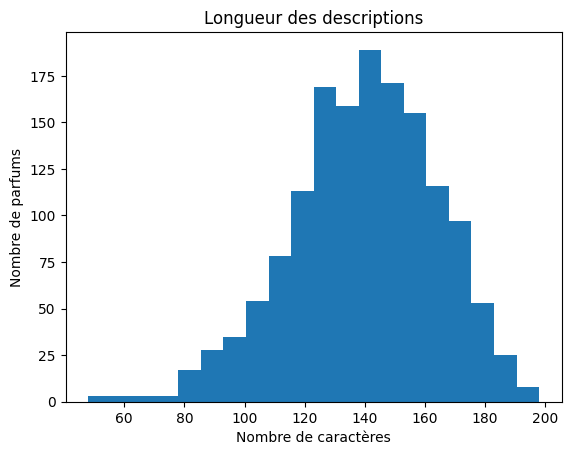

Description la plus courte :  48
Description la pluc longue :  198


In [26]:
df['description'].str.len().plot(kind='hist', bins=20)
plt.title('Longueur des descriptions')
plt.xlabel('Nombre de caractères')
plt.ylabel('Nombre de parfums')
plt.show()

print('Description la plus courte : ', df['description'].str.len().min())
print('Description la pluc longue : ', df['description'].str.len().max())

On observe sur cet histogramme que la majorité des textes ont entre 120 et 170 caractères. La description la plus courte a 48 caractères, et la plus longue en a 198. 

Nous avons donc une bonne quantité de texte à disposition pour créer nos modèles.

## Conclusion

Pour conclure, l'exploration de données nous permet de mieux comprendre la structure et la qualité de notre dataset. Nous avons donc 1779 parfums et 19 variables.

Le dataset contient diverses informations pour caractériser les parfums : familles olfactives, caractéristiques descriptives, notes de tête, de coeur et de fonc, les saisons et moments de la journée adaptés ainsi que des description textuelles. 

Nous constatons cependant plusieurs limites :
- Un grand nombre de valeurs sont manquantes dans les variables year (95%), perfumers (95%) et popularity_rank (59%). D'autres colonnes comme concentration et secondary_family présentent aussi des valeurs manquantes.
- Certaines familles olfactives et caractéristiques sont beaucoup plus représentés que les autres ce qui pourrait fausser les résultats de notre système de recommandation.
- Les variables character, seasons et time_of_day contiennent plusieurs valeurs dans une même cellule séparées par des points virgules. Il faudra trouver un moyen de les structurer.

L'étapes suivantes est donc le nettoyage avant de passer à la modélisation. Il faudra donc traiter les valeurs manquantes, nettoyer et harmoniser les textes, structurer les variables multiples et évaluer la pertinence des variables.